In [ ]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [9]:
import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
# sns.set()
sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
from f2_utils import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches

import time_in_each_roi 

In [10]:
prefix = '/mnt/staging/' # or 
step_0_root = str(STEPS / "step_0") + "/"
step_1_root = str(STEPS / "step_1") + "/"
step_2_root = str(STEPS / "step_2") + "/"
step_3_root = str(STEPS / "step_3") + "/"

fetch_path_S1 = str(PREPARES / "index-S1") + "/"
fetch_path_M2 = str(PREPARES / "index-M2") + "/"
fetch_path_extra = str(PREPARES / "index-extra") + "/"
figure_config_root = str(PREPARES / "config") + "/"

data_root =  str(PREPARES / "epochs-rest-to-running") + "/"

mouse='cm128'

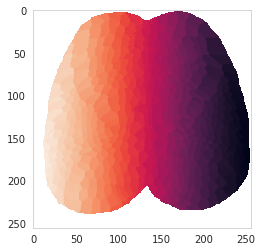

In [11]:
with h5py.File(step_0_root+mouse+'/idx_sorted_500_{}.mat'.format(mouse),'r') as f_idx:

    IDX_sorted = np.array(f_idx['IDX_sorted']).T
    IDX_sorted = IDX_sorted.astype(float)
    IDX_sorted[IDX_sorted==0]='nan'
    num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
    props = regionprops(IDX_sorted.astype(int))
    node_coords = [props[i].centroid for i in range(len(props))]
    node_coords = np.asarray(node_coords, dtype=np.float32)
    
    mask = IDX_sorted >0
    mask = mask.astype(float)
    mask[mask==0]='nan'
plt.imshow(IDX_sorted)

In [12]:
M_raw={}
t1 = 340
with h5py.File(step_1_root+'{}/{}/{}_stim_1.mat'.format(mouse,'1','runB'),'r') as f_H: 
    for key in ['green','lime','red']:
        C = np.array(f_H['C'][key])
        S = np.array(f_H['S'][key])[t1:t1+1,:]
        CS = np.dot(S,C).transpose()

        temp = CS
        temp = temp.reshape((256,256,-1)).transpose((1,0,2))     

        # temp_norm = temp-np.mean(temp[:,:,bsl],axis=-1)[:,:,np.newaxis]
        M_raw[key] = temp


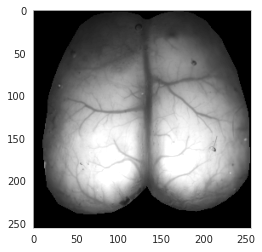

In [13]:
masked_brain = np.multiply(np.squeeze(M_raw['lime']),mask)
masked_brain=np.nan_to_num(masked_brain,0)
plt.imshow(masked_brain,cmap='gray',vmin=0,vmax=5200)

In [14]:
palatte_dict = load_pickle(figure_config_root+'palatte_dict')
# for S1 homunculus
palatte_dict['mouth']=palatte_dict['RM']
palatte_dict['nose']=palatte_dict['RN']
palatte_dict['LV'] = '#ee8c7d'
palatte_dict['tail'] = 'palegreen'

In [15]:
def save_model(model,pkl_filename):
    with open(pkl_filename, 'wb') as file:
        pickle.dump(model, file)

def load_model(pkl_filename):
    with open(pkl_filename, 'rb') as file:
        pickle_model = pickle.load(file)
    return pickle_model


**load data**

In [16]:
M2_ind = load_model(fetch_path_M2+'brightest_frontline_ind-'+mouse)
sensory_ind = load_model(fetch_path_S1+'inferred_brightest_ind_'+mouse)
# all_ind = sensory_ind.copy()
# extra_ind = load_model(fetch_path_extra+'extra_ind_'+mouse)
# extra_extra_ind = load_model(fetch_path_extra+'extra_extra_ind_'+mouse)
# all_ind.update(extra_ind)

# mega_dict_coherence = load_pickle(fetch_path_M1+'mega_dict_coherence_'+mouse)
# # print(mega_dict_coherence.keys())
# M1_ind = mega_dict_coherence['mega_M1_ind_from_coherence']

In [20]:
choice_body_part_dict = {0:'LHP',1:'LFP',2:'LW',3:'LV',
                         4:'LM_M2',5:'LFP_M2',6:'LatM'}

choice_dict = {0:sensory_ind['LHP'],1:sensory_ind['LFP'],2:sensory_ind['LW'],
               3:106,
               4:[],
               5:[],6:62}

In [25]:
palatte_dict = load_pickle(figure_config_root+'palatte_dict')
palatte_dict['LM_M2']='#bf8fc9'
palatte_dict['LFP_M2']='#6dae96'
palatte_dict['LFP_M1']='#4b0082'
palatte_dict['LV']=palatte_dict['RV']
palatte_dict['LW']=palatte_dict['RW']
palatte_dict['LFP']=palatte_dict['RFP']
palatte_dict['LHP']=palatte_dict['RHP']
palatte_dict['LatM']=palatte_dict['ALM']

In [26]:
if mouse =='cm126':
    bregma=np.array([138,122])
if mouse =='cm128':    
    bregma=np.array([135,140])

pixels_per_mm = 29
x_axis = np.divide(np.linspace(-bregma[0],256-bregma[0]-1,256),pixels_per_mm)
y_axis = np.divide(np.linspace(256-bregma[1]-1,-bregma[1],256),pixels_per_mm)

extent = [x_axis[0],x_axis[-1],y_axis[-1],y_axis[0]]

In [27]:
dict_seed_ROI_xy_mice  = load_pickle(figure_config_root+'dict_seed_ROI_xy_mice')

list_choice_M2_l_n_r = ['RFP','RM','RW','RHP','LFP','LM','LW','LHP']
seed_ROI_xy = dict_seed_ROI_xy_mice[mouse]

node_coords_M2 = {}
for i_bdp in range(8):
    bdp = list_choice_M2_l_n_r[i_bdp]
    y_top_left = seed_ROI_xy[bdp]['y_top_left']
    y_botton_right = seed_ROI_xy[bdp]['y_botton_right']
    x_top_left =seed_ROI_xy[bdp]['x_top_left']
    x_botton_right=seed_ROI_xy[bdp]['x_botton_right']
    node_coords_M2[bdp] = np.array([(y_top_left+y_botton_right)/2,(x_top_left+x_botton_right)/2])


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


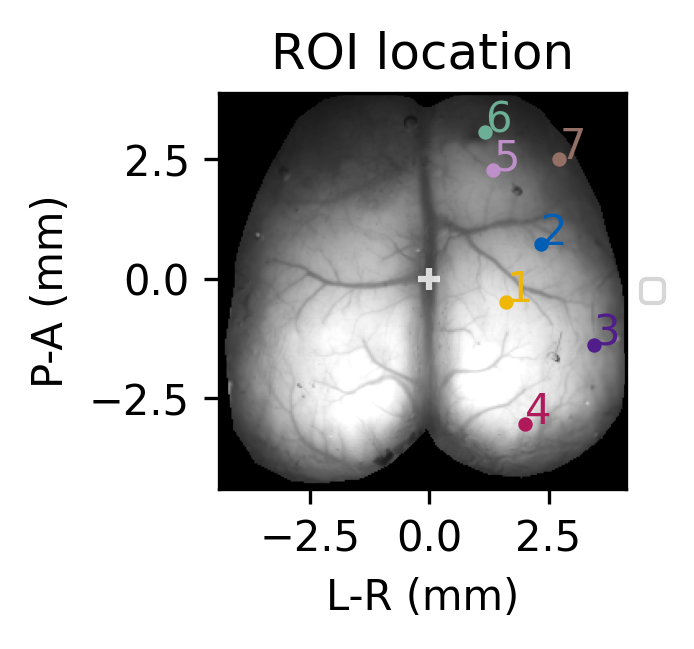

In [28]:
from matplotlib.gridspec import GridSpec
from skimage import measure
from matplotlib import ticker
import matplotlib
plt.style.use('default')

gs = GridSpec(100,100)
# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset=20;
x_width=6;

x_start = x_offset
x_stop = x_start+x_width
ax0 = fig.add_subplot(gs[y_offset:y_offset+6,x_start:x_stop])

ax0.imshow(masked_brain,cmap='gray',vmin=0,vmax=5300,extent=extent)

for i_bdp,bdp_ind in enumerate(choice_body_part_dict):
    y_value = 100+i_bdp*30
    
    ind = choice_dict[i_bdp]
    bdp = choice_body_part_dict[bdp_ind]
    
    if len(bdp.split('_'))==1:
        coord_x = x_axis[int(node_coords[ind,1])];coord_y = y_axis[int(node_coords[ind,0])]
        ax0.scatter(coord_x,coord_y,s=6,color=palatte_dict[bdp])
        ax0.text(coord_x,coord_y,i_bdp+1,
             color=palatte_dict[bdp])
    else:
        coord_x_M2 = x_axis[int(node_coords_M2[bdp.split('_')[0]][0])];coord_y_M2 = y_axis[int(node_coords_M2[bdp.split('_')[0]][1])]
        if bdp.split('_')[1] == 'M2':
            ax0.scatter(coord_x_M2, coord_y_M2, s=6, c=palatte_dict[bdp], zorder=2)
            ax0.text(coord_x_M2,coord_y_M2,i_bdp+1,
                 color=palatte_dict[bdp])
        else:
            coord_x = x_axis[int(node_coords[ind,1])];coord_y = y_axis[int(node_coords[ind,0])]
            ax0.scatter(coord_x,coord_y,s=6,color=palatte_dict[bdp])
            ax0.text(coord_x,coord_y,i_bdp+1,
                 color=palatte_dict[bdp])
    
    # ax0.text(x_axis[int(node_coords[ind,1])],y_axis[int(node_coords[ind,0]-10)],i_bdp+1,
    #      color=palatte_dict[bdp])

    
ax0.set_xlim([-4.4,4.13]);ax0.set_ylim([-4.4,3.9]);
ax0.scatter(0,0,s=30,marker='+',color='white',alpha=0.8) #bregma location
ax0.legend(loc='center left',fontsize=7, bbox_to_anchor=(1, 0.5))
ax0.set_title('ROI location')
ax0.set_xlabel('L-R (mm)')
ax0.set_ylabel('P-A (mm)')

plt.savefig('figS2-ROIs-{}.svg'.format(mouse),format='svg',dpi=300)



In [29]:
behavior_colors = ['#E64B35', '#4DBBD5', '#00A087', '#3C5488',
                  '#F39B7F', '#8491B4', '#91D1C2FF','#7E6148','#B09C85', '#DC0000'
                   ]

In [30]:
col_list = ["grey"] +  ["dark magenta"] + ["emerald green"] + ["golden rod"] + ["tomato"] + ["marine blue"] +["medium blue"]
col_list_palette = sns.xkcd_palette(col_list)

### load rest-running epochs

In [31]:
f = scipy.io.loadmat(data_root+'final_'+mouse+'_filt.mat',
)

M_jrgeco=f['M_jrgeco']
# M_jrgeco_std=f['M_jrgeco_std']
# M_chbt = f['M_chbt']
# M_chbt_std = f['M_chbt_std']
M_pupil_pc=f['M_pupil_pc']
M_face_pc=f['M_face_pc']
M_rotf = f['M_rotf']
M_rotf_raw = f['M_rotf_raw']
M_body_pc = f['M_body_pc']
M_whisk_vel = f['M_whisk_vel']
M_whisk_vel_norm = f['M_whisk_vel_norm']
M_nose_vel_norm=f['M_nose_vel_norm']
M_nose_vel = f['M_nose_vel']
M_LFP_vel=f['M_LFP_vel']
M_LFP_vel_norm=f['M_LFP_vel_norm']
M_RFP_vel=f['M_RFP_vel']
M_RFP_vel_norm=f['M_RFP_vel_norm']
M_pupil_pc_norm=f['M_pupil_pc_norm']
                            
# M_pupil_p_value=f['M_pupil_p_value']
M_day_label=np.squeeze(f['M_day_label'])
M_is_groom=f['M_is_groom']
M_y_rise_LFP_raw = f['M_y_rise_LFP_raw']
M_y_rise_LFP=f['M_y_rise_LFP']
M_ind=np.squeeze(f['M_ind'])
M_ind_stop=np.squeeze(f['M_ind_stop'])

M_mirrorRFP_vel = f['M_mirrorRFP_vel']
M_mirrorRFP_vel_norm = f['M_mirrorRFP_vel_norm']
M_mirrorLFP_vel = f['M_mirrorLFP_vel']
M_mirrorLFP_vel_norm = f['M_mirrorLFP_vel_norm']
M_mirrorRHP_vel = f['M_mirrorRHP_vel']
M_mirrorRHP_vel_norm = f['M_mirrorRHP_vel_norm']
M_mirrorLHP_vel = f['M_mirrorLHP_vel']
M_mirrorLHP_vel_norm = f['M_mirrorLHP_vel_norm']

T_PRE = 120
T_POST = 150
T = T_PRE+T_POST

for i,label in enumerate(M_day_label):
    M_day_label[i]=label.split(' ')[0]
    
# dlc_joint = load_pickle(str(PREPARES / "epochs-running") + "/"+'final_'+mouse+'_raw_data_joint')
# levelnames = dlc_joint.index.get_level_values(0).drop_duplicates()


In [32]:
print(M_jrgeco.shape)

(500, 270, 28)


**normalize**

In [33]:
behaviros_body_w_order = ['norm_M_mirrorRHP_vel_norm',
                     'norm_M_LFP_vel_norm',
                     'norm_M_RFP_vel_norm',
                     'norm_M_rotf']
behaviros_face_w_order = ['norm_M_whisk_vel_norm','norm_M_pupil_pc_norm','norm_M_face_pc']
palette_body=['#0c4666','#adcee9','#f4c784','#e97877']
# palette_face=['#2A7377','#7B4EA1','#D15134','#BAB2AC','#2C5B78','#FFAE4E',]
palette_face=['#7B4EA1','palevioletred','#D15134','#BAB2AC','#2C5B78','#FFAE4E',]
# palette_face = [ '#DC63AA' ,'#232F17', '#D15134']
all_bev_short_dict={'norm_M_whisk_vel_norm':'whisk',
                    'norm_M_nose_vel_norm':'nose',
                    'norm_M_mirrorLHP_vel_norm':'mLHP','norm_M_mirrorRHP_vel_norm':'mRHP',
                     'norm_M_mirrorLFP_vel_norm':'mLFP','norm_M_mirrorRFP_vel_norm':'mRFP','norm_M_LFP_vel_norm':'LFP',
                      'norm_M_RFP_vel_norm':'RFP','norm_M_rotf':'rotary','norm_M_body_pc':'body PC','norm_M_face_pc':'face PC',
                    'norm_M_pupil_pc_norm':'pupil PC'}

In [34]:
for bev in all_bev_short_dict.keys():
    exec("{} = {} - np.mean({}[:T_PRE-40,:],0)[np.newaxis,:]".format(bev,bev[5:],bev[5:]))
    
norm_M_jrgeco = M_jrgeco - np.mean(M_jrgeco[:,:T_PRE-40,:],axis=1)[:,np.newaxis,:]
    

In [35]:
load_filename = data_root+'final_'+mouse+'_MM_full.h5'
# Load and baseline-subtract in blocks of 16 rows. The original built a second
# full-size array here (np.array(...), then MM_jrgeco - np.mean(...)), so it needed two
# copies of the stack live at once: 2 x 31.7 GB = 63.5 GB for cm125, which OOM-kills a
# 48 GB machine (exit 137). This holds one 31.7 GB array plus one ~2 GB block, and
# reads stay sequential; measured on an M4 Pro it finishes in 49 s with 6.4 GB max
# resident.
# Bit-identical to the original: np.array_equal(..., equal_nan=True) is True, because
# blocking along axis 0 leaves the axis-2 reduction untouched. See
# a memory-safe chunked loader.
with h5py.File(load_filename, 'r') as hf:
    dset = hf['MM_jrgeco']
    MM_jrgeco = np.empty(dset.shape, dtype=dset.dtype)
    for i_x0 in range(0, dset.shape[0], 16):
        blk = dset[i_x0:i_x0 + 16]
        MM_jrgeco[i_x0:i_x0 + 16] = blk - np.mean(blk[:,:,:T_PRE-40,:],2)[:,:,np.newaxis,:]
    del blk, dset

In [36]:
# zscore Delta_F/F 
norm_M_jrgeco_zscore = norm_M_jrgeco.copy()
norm_M_jrgeco_zscore = stats.zscore(norm_M_jrgeco_zscore,axis=1)
ss = norm_M_jrgeco.shape
norm_M_jrgeco_zscore_std = np.empty((ss[0],ss[1],0))
for i_bout in range(ss[2]):
    temp = pd.DataFrame(norm_M_jrgeco_zscore[:,:,i_bout]).T.rolling(20).std().T.values
    norm_M_jrgeco_zscore_std=np.append(norm_M_jrgeco_zscore_std,temp[:,:,np.newaxis],axis=2)

    


In [37]:
dict_seed_ROI_xy_mice  = load_pickle(figure_config_root+'dict_seed_ROI_xy_mice')

list_choice_M2_l_n_r = ['RFP','RM','RW','RHP','LFP','LM','LW','LHP']
seed_ROI_xy = dict_seed_ROI_xy_mice[mouse]

jrgeco2plot_M2 = {};node_coords_M2 = {}
for i_bdp in range(8):
    bdp = list_choice_M2_l_n_r[i_bdp]
    y_top_left = seed_ROI_xy[bdp]['y_top_left']
    y_botton_right = seed_ROI_xy[bdp]['y_botton_right']
    x_top_left =seed_ROI_xy[bdp]['x_top_left']
    x_botton_right=seed_ROI_xy[bdp]['x_botton_right']
    node_coords_M2[bdp] = np.array([(y_top_left+y_botton_right)/2,(x_top_left+x_botton_right)/2])
    small_roi_tcs = np.nanmean(np.nanmean(
        MM_jrgeco[x_top_left:x_botton_right,y_top_left:y_botton_right],0),0)
    jrgeco2plot_M2[bdp] = small_roi_tcs
    
H_jrgeco_new_bsl=getH_4D(MM_jrgeco,IDX_sorted)

In [38]:
jrgeco2plot ={}
norm_jrgeco_zscored_std = {}
for i_bdp in range(7):
    bdp = choice_body_part_dict[i_bdp]
    ind = choice_dict[i_bdp]
    if len(bdp.split('_'))==1:
        jrgeco2plot[bdp]=H_jrgeco_new_bsl[ind,:,:]
        norm_jrgeco_zscored_std[bdp] = pd.DataFrame(stats.zscore(jrgeco2plot[bdp],axis=0)).rolling(20,axis=0).std().values
    else:
        if bdp.split('_')[1] == 'M2':
            jrgeco2plot[bdp] = jrgeco2plot_M2[bdp.split('_')[0]]
            norm_jrgeco_zscored_std[bdp] = pd.DataFrame(stats.zscore(jrgeco2plot[bdp],axis=0)).rolling(20,axis=0).std().values
        else:
            jrgeco2plot[bdp] = H_jrgeco_new_bsl[ind,:,:]
            norm_jrgeco_zscored_std[bdp] = pd.DataFrame(stats.zscore(jrgeco2plot[bdp],axis=0)).rolling(20,axis=0).std().values


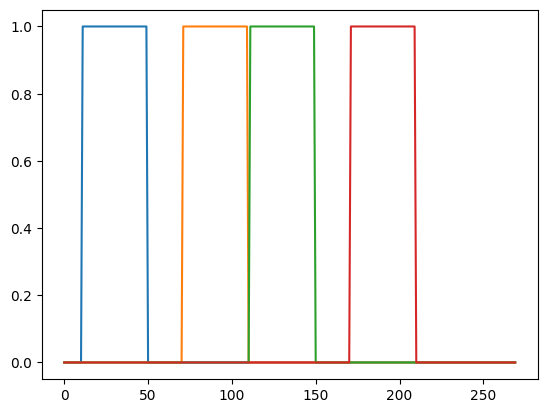

In [39]:
T = norm_M_body_pc.shape[0]
t_ax = np.divide(range(-T_PRE,T-T_PRE),20)
t_start_offset = -0.5 # 0.5 seconds
win1 = np.logical_and(t_ax>-5+t_start_offset,t_ax<-3+t_start_offset)
win2 = np.logical_and(t_ax>-2+t_start_offset,t_ax<-0+t_start_offset)
win3 = np.logical_and(t_ax>0+t_start_offset,t_ax<2+t_start_offset)
win4 = np.logical_and(t_ax>3+t_start_offset,t_ax<5+t_start_offset)


plt.plot(win1)
plt.plot(win2)
plt.plot(win3)
plt.plot(win4)
# plt.xlim([290,300])|

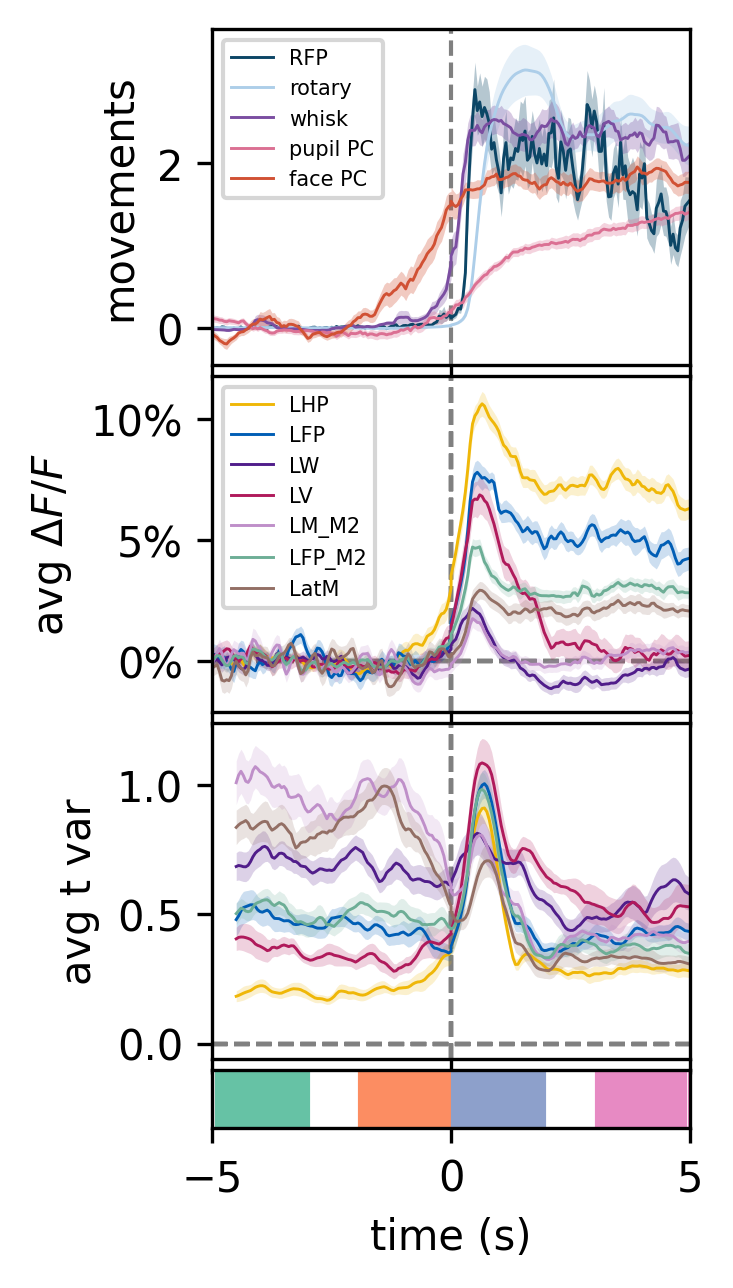

In [41]:
from matplotlib.gridspec import GridSpec
from matplotlib import colors
from skimage import measure
import matplotlib
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
fmt = lambda x, pos: '{:.0%}'.format(x)
plt.style.use('default')
gs = GridSpec(100,100)
# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)


y_offset = 20;x_offset=20;x_width=5

# behavior (body and facial movements)
x_start = x_offset 
x_stop = x_start+7
y_start = y_offset 
y_stop = y_start+5
for i_ax in range(0,3):
    exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    y_start = y_stop
    y_stop = y_start+5
    # if i_ax < 2:
    exec("ax{}.set_xticklabels([])".format(i_ax)) 
    
ax3 = fig.add_subplot(gs[y_start:y_start+1,x_start:x_stop])
ax3.set_yticks([])

########################################
########################################
lwidth = 0.7


t_frame_trimmed = np.linspace(-100,100,200).astype('int')
t_ax_trimmed = np.divide(t_frame_trimmed,20)

# ampltitude
for i_bdp in range(7):
    bdp = choice_body_part_dict[i_bdp]
    ind = choice_dict[i_bdp]
    
    data2plot = jrgeco2plot[bdp][T_PRE-10-100:T_PRE-10+100,:]
    
    avg = np.mean(data2plot,axis=-1)
    sem = stats.sem(data2plot,axis=-1)
    ax1.plot(t_ax_trimmed,avg,color=palatte_dict[bdp],linewidth = lwidth,label=bdp)
    ax1.fill_between(t_ax_trimmed, avg - sem,avg + sem,color=palatte_dict[bdp],alpha=0.2,lw=0)
    ax1.axvline(0,linewidth=1,linestyle='dashed',color='gray',zorder=-9999)
    ax1.axhline(0,linewidth=1,linestyle='dashed',color='gray',zorder=-9999)
    ax1.set_yticks([0,0.05,0.1])
    vals = ax1.get_yticks()
    ax1.set_yticklabels(['{:,.0%}'.format(x) for x in vals])
    ax1.set_xlim([t_ax_trimmed[0],t_ax_trimmed[-1]])
    # ax2.set_yticklabels([])

    
for i_bdp in range(7):
    bdp = choice_body_part_dict[i_bdp]
    ind = choice_dict[i_bdp]
    
    data2plot = norm_jrgeco_zscored_std[bdp][T_PRE-10-100:T_PRE-10+100,:]
    
    avg = np.mean(data2plot,axis=-1)
    sem = stats.sem(data2plot,axis=-1)
    ax2.plot(t_ax_trimmed,avg,color=palatte_dict[bdp],linewidth = lwidth,label=bdp)
    ax2.fill_between(t_ax_trimmed, avg - sem,avg + sem,lw=0,color=palatte_dict[bdp],alpha=0.2)
    ax2.axvline(0,linewidth=1,linestyle='dashed',color='gray',zorder=-9999)
    # ax1.set_yticks([-0.2,0,0.02])
    ax2.axhline(0,linewidth=1,linestyle='dashed',color='gray',zorder=-9999)
    ax2.set_xlim([t_ax_trimmed[0],t_ax_trimmed[-1]])
    # ax1.set_xticklabels([])


    
# NOW plot behavior
# body movements

behaviros_body_w_order = [
                     'norm_M_RFP_vel_norm',
                     'norm_M_rotf']
behaviros_face_w_order = ['norm_M_whisk_vel_norm','norm_M_pupil_pc_norm','norm_M_face_pc']


for i_behavior,behavior in enumerate(behaviros_body_w_order):
    exec("beh2plot = {}[T_PRE-10-100:T_PRE-10+100,:]".format(behavior))
    avg = np.mean(beh2plot,axis=1)#+i_behavior*2.5
    sem = stats.sem(beh2plot,axis=1)
    ax0.plot(t_ax_trimmed,avg,color=palette_body[i_behavior],linewidth = lwidth, label=all_bev_short_dict[behavior])
    ax0.fill_between(t_ax_trimmed, avg - sem,avg + sem,lw=0,color=palette_body[i_behavior],alpha=0.3)
    ax0.set_xlim([t_ax_trimmed[0],t_ax_trimmed[-1]])
    # ax2.text(t_ax[0]+0.3,i_behavior*2.5+0.35,all_bev_short_dict[behavior],color=behavior_colors[i_behavior],fontsize=10)


ax0.axvline(0,linewidth=1,linestyle='dashed',color='gray',zorder=-9999)
  



for i_behavior,behavior in enumerate(behaviros_face_w_order):
    exec("beh2plot = {}[T_PRE-10-100:T_PRE-10+100,:]".format(behavior))
    avg = np.mean(beh2plot,axis=1)#+i_behavior*2.5
    sem = stats.sem(beh2plot,axis=1)
    ax0.plot(t_ax_trimmed,avg,color=palette_face[i_behavior],linewidth = lwidth,label=all_bev_short_dict[behavior])
    ax0.fill_between(t_ax_trimmed, avg - sem,avg + sem,lw=0,color=palette_face[i_behavior],alpha=0.3)
    ax0.set_xlim([t_ax_trimmed[0],t_ax_trimmed[-1]])
    # ax2.text(t_ax[0]+0.3,i_behavior*2.5+0.35,all_bev_short_dict[behavior],color=behavior_colors[i_behavior],fontsize=10)


for i_win,win in enumerate(['win1','win2','win3','win4']):
    exec("win_here = {}[T_PRE-10-100:T_PRE-10+100]".format(win))
    ax3.vlines(t_ax_trimmed[np.where(win_here==True)], 0, 0.5,linewidth=1,color=sns.color_palette("Set2")[i_win])
    ax3.vlines(0, 8, 9,linewidth=10,color=sns.color_palette("Set2")[i_win],label=win_here)#for the legend
ax3.set_ylim([0,0.5])
ax3.set_xlim([t_ax_trimmed[0],t_ax_trimmed[-1]])
    
####
ax0.legend(fontsize=5)
ax1.legend(fontsize=5)
# ax2.legend(fontsize=5)
ax1.set_ylabel('avg $\Delta F/F$')
ax2.set_ylabel('avg t var')
ax0.set_ylabel('movements');  
ax3.set_xlabel('time (s)')
###
plt.savefig('figS2-{}-TCs.svg'.format(mouse),format='svg',dpi=300)

# brain

In [43]:
with h5py.File(figure_config_root+'mask_midline_'+mouse+'.mat','r') as f_midline:
    mask_midline = np.array(f_midline['mask_midline']).T

In [44]:
map_norm_M_jrgeco_by_win = {}
map_norm_M_jrgeco_zscore_std_by_win = {}
for i_win,win in enumerate(['win1','win2','win3','win4']):
    
    exec("avg_temp = np.nanmean(np.nanmean(norm_M_jrgeco[:,{},:],axis=1),axis=-1)".format(win))
    map_norm_M_jrgeco_by_win[win] = np.multiply(show_map(avg_temp,
                                      [0,2],cmap='coolwarm',if_return_map=True,IDX_sorted=IDX_sorted),
                                             mask_midline)   


    exec("avg_temp = np.nanmean(np.nanmean(norm_M_jrgeco_zscore_std[:,{},:],axis=1),axis=-1)".format(win))
    map_norm_M_jrgeco_zscore_std_by_win[win] = np.multiply(show_map(avg_temp,
                                      [0,2],cmap='coolwarm',if_return_map=True,IDX_sorted=IDX_sorted),
                                            mask_midline)   



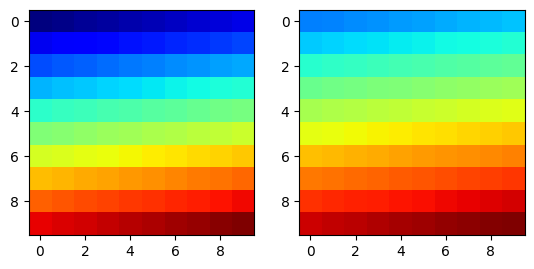

In [45]:
import matplotlib.colors as colors
def truncate_colormap(cmap, minval=0.0, maxval=1.0, n=100):
    new_cmap = colors.LinearSegmentedColormap.from_list(
        'trunc({n},{a:.2f},{b:.2f})'.format(n=cmap.name, a=minval, b=maxval),
        cmap(np.linspace(minval, maxval, n)))
    return new_cmap

arr = np.linspace(0, 50, 100).reshape((10, 10))
fig, ax = plt.subplots(ncols=2)

cmap = plt.get_cmap('jet')
new_cmap = truncate_colormap(cmap, 0.25, 1)
ax[0].imshow(arr, interpolation='nearest', cmap=cmap)
ax[1].imshow(arr, interpolation='nearest', cmap=new_cmap)
plt.show()

cmap = plt.get_cmap('jet')
new_cmap = truncate_colormap(cmap, 0.25, 1)

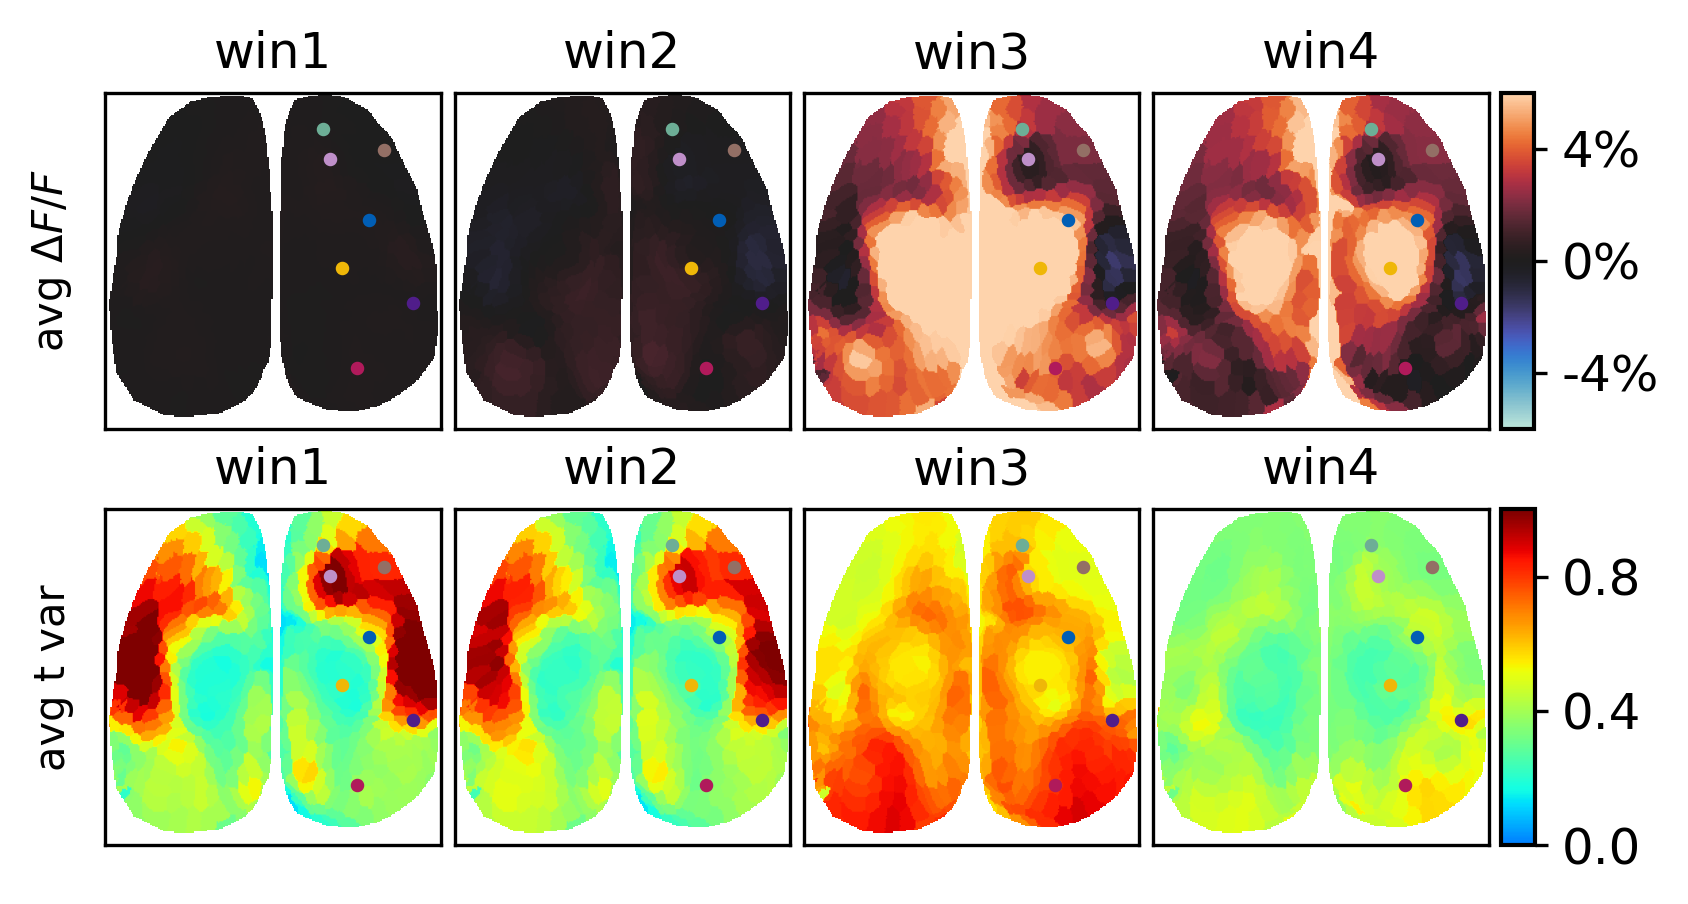

In [46]:
from matplotlib.gridspec import GridSpec
from matplotlib import colors
from skimage import measure
import matplotlib
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
fmt = lambda x, pos: '{:.0%}'.format(x)
plt.style.use('default')
gs = GridSpec(100,100)
# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)


y_offset = 20;x_offset=20;x_width=5


# temporal std average brain map (rest and run)
x_start = x_offset 
x_stop = x_offset+x_width
for i_ax in range(0,4):
    exec("ax{} = fig.add_subplot(gs[y_offset:y_offset+5,x_start:x_stop])".format(i_ax))
    x_start = x_stop
    x_stop = x_start + x_width
    exec("ax{}.set_xticks([])".format(i_ax))
    exec("ax{}.set_yticks([])".format(i_ax))    

ax990 = fig.add_subplot(gs[y_offset:y_offset+5,x_start:x_start+2])

x_start = x_offset 
x_stop = x_offset+x_width
for i_ax in range(4,8):
    exec("ax{} = fig.add_subplot(gs[y_offset+6:y_offset+11,x_start:x_stop])".format(i_ax))
    x_start = x_stop
    x_stop = x_start + x_width
    exec("ax{}.set_xticks([])".format(i_ax))
    exec("ax{}.set_yticks([])".format(i_ax))    

ax991 = fig.add_subplot(gs[y_offset+6:y_offset+11,x_start:x_start+2])
########################################
########################################



# t_frame_trimmed = np.linspace(-100,100,200).astype('int')
# t_ax_trimmed = np.divide(t_frame_trimmed,20)


# map_norm_M_jrgeco_by_win 
# map_norm_M_jrgeco_zscore_std_by_win 
for i_win,win in enumerate(['win1','win2','win3','win4']):
    exec("sbp1 = ax{}.imshow(map_norm_M_jrgeco_by_win[win],vmin=-0.06,vmax=0.06,aspect='equal',cmap='icefire')".format(i_win))
    exec("ax{}.set_title(win)".format(i_win))
    exec("ax{}.set_xlim([8,256]);ax{}.set_ylim([248,0])".format(i_win,i_win))
    for i_bdp,bdp_ind in enumerate(choice_body_part_dict):
        ind = choice_dict[i_bdp]
        bdp = choice_body_part_dict[bdp_ind]
        if len(bdp.split('_'))==1:
            exec("ax{}.scatter(node_coords[ind,1],node_coords[ind,0],s=5,color=palatte_dict[bdp])".format(i_win))
        else:
            if bdp.split('_')[1] == 'M2':
                exec("ax{}.scatter(node_coords_M2[bdp.split('_')[0]][0], node_coords_M2[bdp.split('_')[0]][1], s=5, c=palatte_dict[bdp], zorder=2)".format(i_win))
            else:
                exec("ax{}.scatter(node_coords[ind,1],node_coords[ind,0],s=5,color=palatte_dict[bdp])".format(i_win))


# #####brain maps

for i_win,win in enumerate(['win1','win2','win3','win4']):
    exec("sbp2 = ax{}.imshow(map_norm_M_jrgeco_zscore_std_by_win[win],vmin=-0.0,vmax=1,aspect='equal',cmap=new_cmap)".format(i_win+4))
    exec("ax{}.set_title(win)".format(i_win+4))
    exec("ax{}.set_xlim([8,256]);ax{}.set_ylim([248,0])".format(i_win+4,i_win+4))
    for i_bdp,bdp_ind in enumerate(choice_body_part_dict):
        ind = choice_dict[i_bdp]
        bdp = choice_body_part_dict[bdp_ind]
        if len(bdp.split('_'))==1:
            exec("ax{}.scatter(node_coords[ind,1],node_coords[ind,0],s=5,color=palatte_dict[bdp])".format(i_win+4))
        else:
            if bdp.split('_')[1] == 'M2':
                exec("ax{}.scatter(node_coords_M2[bdp.split('_')[0]][0], node_coords_M2[bdp.split('_')[0]][1], s=5, c=palatte_dict[bdp], zorder=2)".format(i_win+4))
            else:
                exec("ax{}.scatter(node_coords[ind,1],node_coords[ind,0],s=5,color=palatte_dict[bdp])".format(i_win+4))
    

for i_count,i_ax in enumerate([3,7]):
    if i_ax==3:
        exec("cb = fig.colorbar(sbp1, cax=ax99{},fraction=0.5,orientation='vertical',format=FuncFormatter(fmt));".format(i_count))
    else:
        exec("cb = fig.colorbar(sbp2, cax=ax99{},fraction=0.5,orientation='vertical');".format(i_count))
    cb.ax.tick_params(labelsize=12,length=3,color='black')
    cb.ax.yaxis.tick_right()       
    cb.outline.set_edgecolor('black')
    cb.outline.set_linewidth(1)
    tick_locator = ticker.MaxNLocator(nbins=3)
    cb.locator = tick_locator
    cb.update_ticks()
    if i_ax==3:
        exec("ax99{}.set_aspect(85);ax99{}.set_anchor('W')".format(i_count,i_count))
    if i_ax==7:
        exec("ax99{}.set_aspect(10);ax99{}.set_anchor('W')".format(i_count,i_count))
        
        
# ####
ax0.set_ylabel('avg $\Delta F/F$')
ax4.set_ylabel('avg t var')
# ax2.legend(fontsize=5)
# ###
plt.savefig('figS2-brain-maps-movie-{}.svg'.format(mouse),format='svg',dpi=300)

# STATS

In [61]:
map_norm_H_by_win = {}
map_norm_H_zscore_std_by_win = {}
for i_win,win in enumerate(['win1','win2','win3','win4']):
    map_norm_H_by_win[win] = {}
    for i_bdp in range(7):
        bdp = choice_body_part_dict[i_bdp]
        exec("temps = np.nanmean(jrgeco2plot[bdp][{},:],axis=0)".format(win))
        map_norm_H_by_win[win][bdp]=temps

    map_norm_H_zscore_std_by_win[win]={}
    for i_bdp in range(7):
        bdp = choice_body_part_dict[i_bdp]
        exec("temps = np.nanmean(norm_jrgeco_zscored_std[bdp][{},:],axis=0)".format(win))
        map_norm_H_zscore_std_by_win[win][bdp]=temps


In [62]:
diff_pot,paired_t_pot=pd.DataFrame(),pd.DataFrame()
for i_region,key in enumerate(choice_body_part_dict):
    region = choice_body_part_dict[key]
    ind = choice_dict[key]
    
    diff_temp=pd.DataFrame()
    paired_t_temp=pd.DataFrame(columns=['std_t','std_signif','mean_t','mean_signif','region','mouse'])
    diff_temp['std_diff'] = map_norm_H_zscore_std_by_win['win4'][region] - map_norm_H_zscore_std_by_win['win1'][region]  #Y_3['std_'+region]-Y_1['std_'+region]
    results = scipy.stats.wilcoxon(map_norm_H_zscore_std_by_win['win4'][region],map_norm_H_zscore_std_by_win['win1'][region])
    paired_t_temp.loc[i_region,'std_t'],paired_t_temp.loc[i_region,'std_signif'] = results[0],results[1]
    diff_temp['mean_diff'] = map_norm_H_by_win['win4'][region] - map_norm_H_by_win['win1'][region]
    results= scipy.stats.wilcoxon(map_norm_H_by_win['win4'][region],map_norm_H_by_win['win1'][region])
    paired_t_temp.loc[i_region,'mean_t'],paired_t_temp.loc[i_region,'mean_signif'] = results[0],results[1]
    
    paired_t_temp.loc[i_region,'region']=region
    paired_t_temp.loc[i_region,'mouse']=mouse

    
    diff_temp['region']=region
    diff_temp['mouse']=mouse
    diff_pot = pd.concat([diff_pot, diff_temp])
    paired_t_pot = pd.concat([paired_t_pot, paired_t_temp])

In [63]:
stats_dict = {'diff_pot':diff_pot,
             'paired_t_pot':paired_t_pot}

In [64]:
save_root = str(FIGURES / "figure3") + "/"
save_pickle(stats_dict,save_root+'stats_'+mouse)

# END